In [1]:
import os
import pickle
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon
import matplotlib.pyplot as plt

In [2]:
# Set the person variable and bin size
# This should be set to the person you are working with, e.g., "CRC_P1, CRC_P2, CRC_P5" or "Normal_P3, Normal_P5" 
# (here based on the 10x genomics datasets)
person = "CRC_P2"
resolution = "002um"

# Plottig the Nuclei
The first cell plots ALL nuclei that were denoted in the pickle files storing the polygons.

The second cell only plots the nuclei that overlap with barcodes from the Visium HD results. 

Number of nuclei found: 1263888


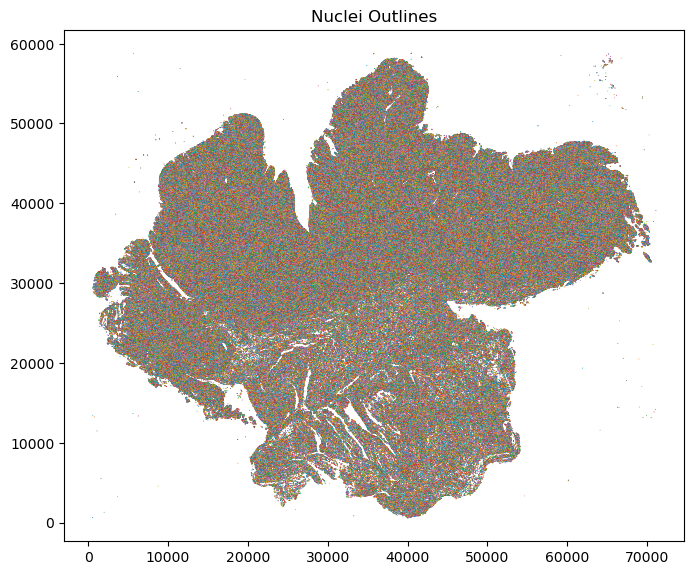

In [3]:
# Load polys
# Note: curent polys are the ones from NucleiSegmentation.py and the ong image
with open(f"output/{person}/{resolution}/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

print(f"Number of nuclei found: {len(polys['coord'])}")
# Plot outlines
fig, ax = plt.subplots(figsize=(8, 8))
for y_coords, x_coords in polys['coord']:
    ax.plot(x_coords, y_coords, linewidth=0.5)

ax.set_aspect('equal')
ax.set_title("Nuclei Outlines")
plt.show()


Note: if you look in test_file_contents.ipynb, you can see that there are some negative pixel values in the y column. This is most likely due to the fact, that the tissue on the y-column is very close to the 0-point, meaning some of the barcodes have a negative value. 

However, excluding these, these are the minimum and maximum values for x and y pixel coordinates for CRC_P1:

smallest: (12134.246844050029, 0.01616907989636651)[x, y]

biggest: (36818.02543268167, 24440.315118149927)[x, y]

NOTE: numpy requires format (row, column) == (y, x), which is why they are "inverted" here. 


Smallest positive value in pxl_row_in_fullres: 0.0003888271621902038
Smallest positive value in pxl_col_in_fullres: 40580.8509761489
Biggest positive value in pxl_row_in_fullres: 22701.120312201965
Biggest positive value in pxl_col_in_fullres: 65345.61240968113
Number of nuclei found: 1109907


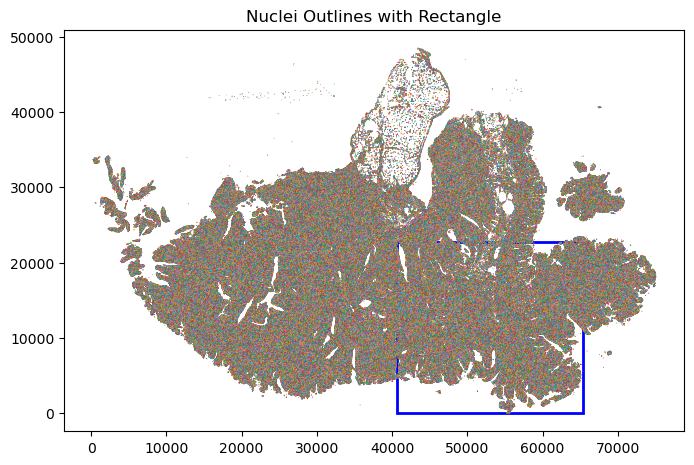

In [3]:
import pandas as pd 
tissuepositions = pd.read_parquet(f"../data/{person}/output/binned_outputs/square_{resolution}/spatial/tissue_positions.parquet")

row = "pxl_row_in_fullres"
smallest_row_gt_zero = tissuepositions.loc[tissuepositions[row] > 0, row].min()
print(f"Smallest positive value in {row}: {smallest_row_gt_zero}")

col = "pxl_col_in_fullres"
smallest_col_gt_zero = tissuepositions.loc[tissuepositions[col] > 0, col].min()
print(f"Smallest positive value in {col}: {smallest_col_gt_zero}")

biggest_row_gt_zero = tissuepositions.loc[tissuepositions[col] > 0, row].max()
print(f"Biggest positive value in {row}: {biggest_row_gt_zero}")

biggest_col_gt_zero = tissuepositions.loc[tissuepositions[col] > 0, col].max()
print(f"Biggest positive value in {col}: {biggest_col_gt_zero}")

# Load polys
# Note: curent polys are the ones from NucleiSegmentation.py and the ong image
with open(f"output/{person}/{resolution}/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

print(f"Number of nuclei found: {len(polys['coord'])}")
# Plot outlines
fig, ax = plt.subplots(figsize=(8, 8))
for y_coords, x_coords in polys['coord']:
    ax.plot(x_coords, y_coords, linewidth=0.5)

# Add rectangle with given pixel coordinates
import matplotlib.patches as patches
width = biggest_col_gt_zero - smallest_col_gt_zero
height = biggest_row_gt_zero - smallest_row_gt_zero

rect = patches.Rectangle((smallest_col_gt_zero, smallest_row_gt_zero), width, height, linewidth=2, edgecolor='blue', facecolor='none')
ax.add_patch(rect)

ax.set_aspect('equal')
ax.set_title("Nuclei Outlines with Rectangle")
plt.show()

Number of uniqe IDs: 305777


100%|██████████| 305777/305777 [00:07<00:00, 38592.28it/s]


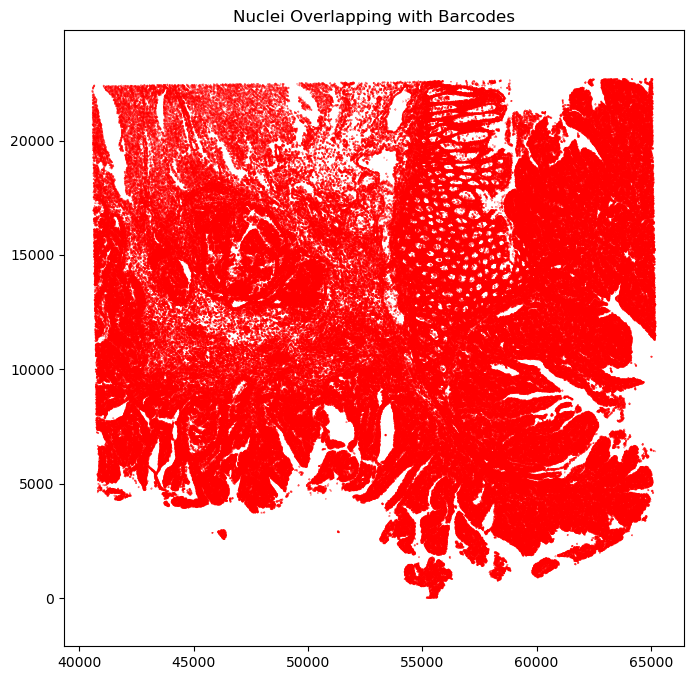

In [4]:
with open(f"output/{person}/{resolution}/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

# Load csv with barcode matches
result_df = pd.read_csv(f"output/{person}/{resolution}/Nuclei_Barcode_Map.csv")

# Extract overlapping IDs within one or several nuclei polygons
matched_ids = result_df["id"].unique()
print(f"Number of uniqe IDs: {len(matched_ids)}")

from tqdm import tqdm  # optional, for progress bar

# Create all polygons with their IDs
geometries = []
ids = []

#TODO: switch so that matched_ids are looped through instead of all polys
geometries = []
ids = []

for matched_id in tqdm(matched_ids):
    idx = int(matched_id.split("_")[1]) - 1  # Convert "ID_5" to 4
    y_coords, x_coords = polys['coord'][idx]
    polygon = Polygon(zip(x_coords, y_coords))
    geometries.append(polygon)
    ids.append(matched_id)

# Build GeoDataFrame
gdf = gpd.GeoDataFrame({"id": ids, "geometry": geometries})

# Plot the nuclei that overlap with barcodes
# Note: Adjust the edgecolor and facecolor as needed
fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(ax=ax, edgecolor='red', facecolor='none', linewidth=1)
plt.title("Nuclei Overlapping with Barcodes")
plt.axis("equal")
plt.show()

In [6]:
# print the first 5 nuclei coordinates
for i, (y_coords, x_coords) in enumerate(polys['coord'][:5]):
    print(f"Nucleus {i}:")
    print("  y_coords:", y_coords)
    print("  x_coords:", x_coords)

Nucleus 0:
  y_coords: [1688.         1691.26867676 1694.59350586 1697.53857422 1700.51647949
 1702.94970703 1705.01989746 1705.89074707 1707.03637695 1706.12438965
 1705.40344238 1703.84228516 1701.15795898 1698.07568359 1694.6217041
 1691.09094238 1688.         1685.17333984 1682.42041016 1679.79260254
 1677.09936523 1674.66455078 1672.27868652 1671.27233887 1669.97509766
 1670.37866211 1671.11157227 1672.98449707 1675.37365723 1678.21911621
 1681.25       1684.61523438]
  x_coords: [549.125      548.43255615 547.91827393 546.27545166 544.51647949
 541.98907471 539.04986572 535.55871582 532.         528.39483643
 524.79125977 521.41455078 518.84210205 516.9206543  516.01373291
 516.46075439 516.70941162 517.78948975 518.52966309 519.71679688
 521.09936523 523.08953857 525.48797607 528.67266846 532.
 535.50512695 538.99542236 542.03308105 544.62628174 546.63812256
 548.29595947 549.01611328]
Nucleus 1:
  y_coords: [2328.         2330.97827148 2333.81176758 2336.18188477 2338.51171875


# Compare bins in cells vs bins in image

### Plot all filtered nuclei
1. We plot ALL nuclei found by STARDIST.
2. Plot only nucli after filtering for UMI counts, extremely large cells and overlaying or broken cells. 
This is based on `count_area_filtered_adata.h5ad`.
3. We then plot the same nuclei, but with the tissue image below.

In [3]:
import gc
import geopandas as gpd
import json
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd 
import pickle
import pyvips
import scanpy as sc
from shapely import affinity

## Set variables
person = "CRC_P2" 

## Data Loading
custom_binning_path = f"output/{person}/002um/custom_binning"
spatial_path = f"../data/{person}/output/binned_outputs/square_002um/spatial"

adata_filtered_nuclei = sc.read_h5ad(os.path.join(custom_binning_path, "count_area_filtered_adata.h5ad"))
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.set_index("id")

ground_truth = pd.read_csv(f"../data/{person}/ground_truth/2um_squares_annotation.csv", delimiter='\t', header=None, names=['barcode', 'tissuetype'])

with open(f"output/{person}/002um/polys_FullSection.pckl", "rb") as f:
    nuclei_geometry = pickle.load(f)

filtered_nuclei_geometry = gpd.read_parquet(os.path.join(custom_binning_path, "nuclei_geometry.parquet"))
filtered_nuclei_geometry = filtered_nuclei_geometry.set_index("id")

# with open(os.path.join(spatial_path, "scalefactors_json.json"), 'r') as f:
#    scalefactors = json.load(f)

tissue_positions = pd.read_parquet(os.path.join(spatial_path, "tissue_positions.parquet"))


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


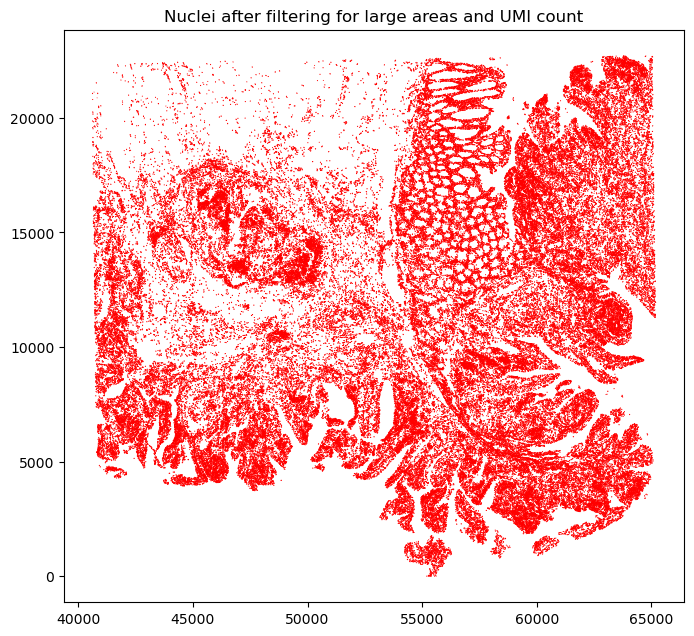

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
filtered_nuclei_geometry.plot(ax=ax, color="red", edgecolor="red", linewidth=0.5)
ax.set_title("Nuclei after filtering for large areas and UMI count")
plt.show()

In [6]:
col = "pxl_col_in_fullres"
row = "pxl_row_in_fullres"
xmin = math.floor(tissue_positions.loc[tissue_positions[col] > 0, col].min())
xmax = math.ceil(tissue_positions.loc[tissue_positions[col] > 0, col].max())
ymin = math.floor(tissue_positions.loc[tissue_positions[row] > 0, row].min())
ymax = math.ceil(tissue_positions.loc[tissue_positions[row] > 0, row].max())

image = pyvips.Image.new_from_file(f"../data/{person}/input/Visium_HD_Human_Colon_Cancer_P2_tissue_image.btf", access="sequential")
cropped = image.crop(xmin, ymin, xmax - xmin, ymax - ymin)


# Shift geometries by -x_min, -y_min
gdf_cropped = filtered_nuclei_geometry.copy()
gdf_cropped["geometry"] = gdf_cropped["geometry"].translate(xoff=-xmin, yoff=-ymin)

# Convert cropped VIPS image to numpy array (RGB)
img_np = np.ndarray(
    buffer=cropped.write_to_memory(),
    dtype=np.uint8,
    shape=[cropped.height, cropped.width, cropped.bands]
)

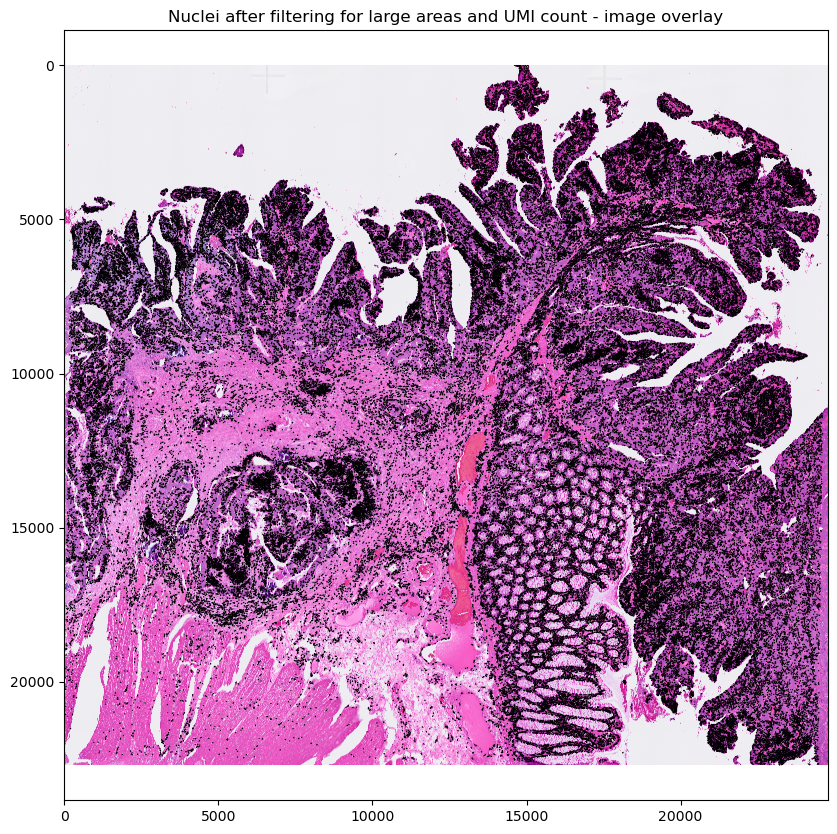

In [7]:
# Plot
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_title("Nuclei after filtering for large areas and UMI count - image overlay")
ax.imshow(img_np, origin="upper")

# Overlay polygons
gdf_cropped.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.5)
plt.show()

### Plotting ground truths

1. Ground truth based on ALL bins (in tisssue)
2. Ground truth only for bins in nuclei


In [8]:
# Merge for pixel positions
ground_truth['tissuetype_id'] = pd.factorize(ground_truth['tissuetype'])[0]

ground_truth = pd.merge(ground_truth, tissue_positions, on='barcode', how='left')
full_size = tissue_positions.shape[0]
print("Total barcode count: ", full_size)

ground_truth = ground_truth[ground_truth["in_tissue"] != 0]
ground_truth = ground_truth[ground_truth["tissuetype"] != "Outside"]
print("Barcodes within tissue - size: ", full_size - (full_size - ground_truth.shape[0]))

ground_truth = ground_truth.rename(columns={'pxl_col_in_fullres': 'x_pixel', 'pxl_row_in_fullres': 'y_pixel'})

Total barcode count:  11222500
Barcodes within tissue - size:  8731368


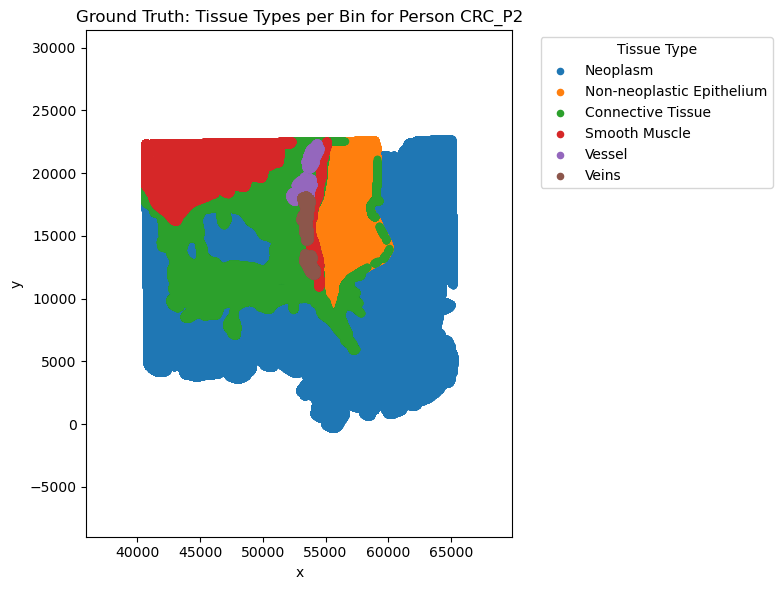

In [9]:
# Color map for cell types
unique_tissuetypes = ground_truth['tissuetype'].unique()
colors = plt.cm.tab10(range(len(unique_tissuetypes)))  # or tab20 for more

# Create a mapping from celltype to color
color_dict = {ct: colors[i] for i, ct in enumerate(unique_tissuetypes)}

# Plot each cell type separately
plt.figure(figsize=(8,6))
for celltype in unique_tissuetypes:
    subset = ground_truth[ground_truth['tissuetype'] == celltype]
    plt.scatter(subset['x_pixel'], subset['y_pixel'],
                c=[color_dict[celltype]],
                label=celltype,  # <-- use string label
                s=20)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Ground Truth: Tissue Types per Bin for Person {person}')
plt.legend(title='Tissue Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axis('equal')
plt.tight_layout()
plt.show()
plt.show()
